<a href="https://colab.research.google.com/github/lnambiar18/Nambiar_Lohit_HW6_DSCI552/blob/main/Nambiar_Lohit_HW6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1>Nambiar_Lohit_HW6</h1></center>

Name: Lohit Nambiar
<br>
Github Username: lnambiar18
<br>
USC ID: 8395177707

## 1. Tree-Based Methods

Import packages

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [16]:
train = pd.read_csv("aps_failure_training_set.csv", skiprows = 20, na_values = "na")
test = pd.read_csv("aps_failure_test_set.csv", skiprows = 20, na_values = "na")

print(train.head())

  class  aa_000  ab_000        ac_000  ad_000  ae_000  af_000  ag_000  ag_001  \
0   neg   76698     NaN  2.130706e+09   280.0     0.0     0.0     0.0     0.0   
1   neg   33058     NaN  0.000000e+00     NaN     0.0     0.0     0.0     0.0   
2   neg   41040     NaN  2.280000e+02   100.0     0.0     0.0     0.0     0.0   
3   neg      12     0.0  7.000000e+01    66.0     0.0    10.0     0.0     0.0   
4   neg   60874     NaN  1.368000e+03   458.0     0.0     0.0     0.0     0.0   

   ag_002  ...     ee_002    ee_003    ee_004    ee_005    ee_006    ee_007  \
0     0.0  ...  1240520.0  493384.0  721044.0  469792.0  339156.0  157956.0   
1     0.0  ...   421400.0  178064.0  293306.0  245416.0  133654.0   81140.0   
2     0.0  ...   277378.0  159812.0  423992.0  409564.0  320746.0  158022.0   
3     0.0  ...      240.0      46.0      58.0      44.0      10.0       0.0   
4     0.0  ...   622012.0  229790.0  405298.0  347188.0  286954.0  311560.0   

     ee_008  ee_009  ef_000  eg_000  


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Some ways to deal with missing data include deleting rows or columns with missing values, filling them with the mean or median, and using methods like KNN or regression to estimate the missing values. I would use median imputation for this dataset since the sensor values are numeric and may have abnormal values, the median is a good choice because extreme values affect it less than they affect the mean.

In [17]:
for column in train.columns:
    if column != "class":
        train[column] = train[column].fillna(train[column].median())
        test[column] = test[column].fillna(test[column].median())

#### (ii) Calculate the coefficient of variation

In [18]:
for column in train.drop(columns=["class"]).columns[:5]:
    cv = train[column].std() / train[column].mean()
    print(column, cv)

aa_000 2.450937577943998
ab_000 10.383493866617679
ac_000 2.310240655003492
ad_000 244.32281575936082
ae_000 24.200136597481663


#### (iii) Plot a correlation matrix

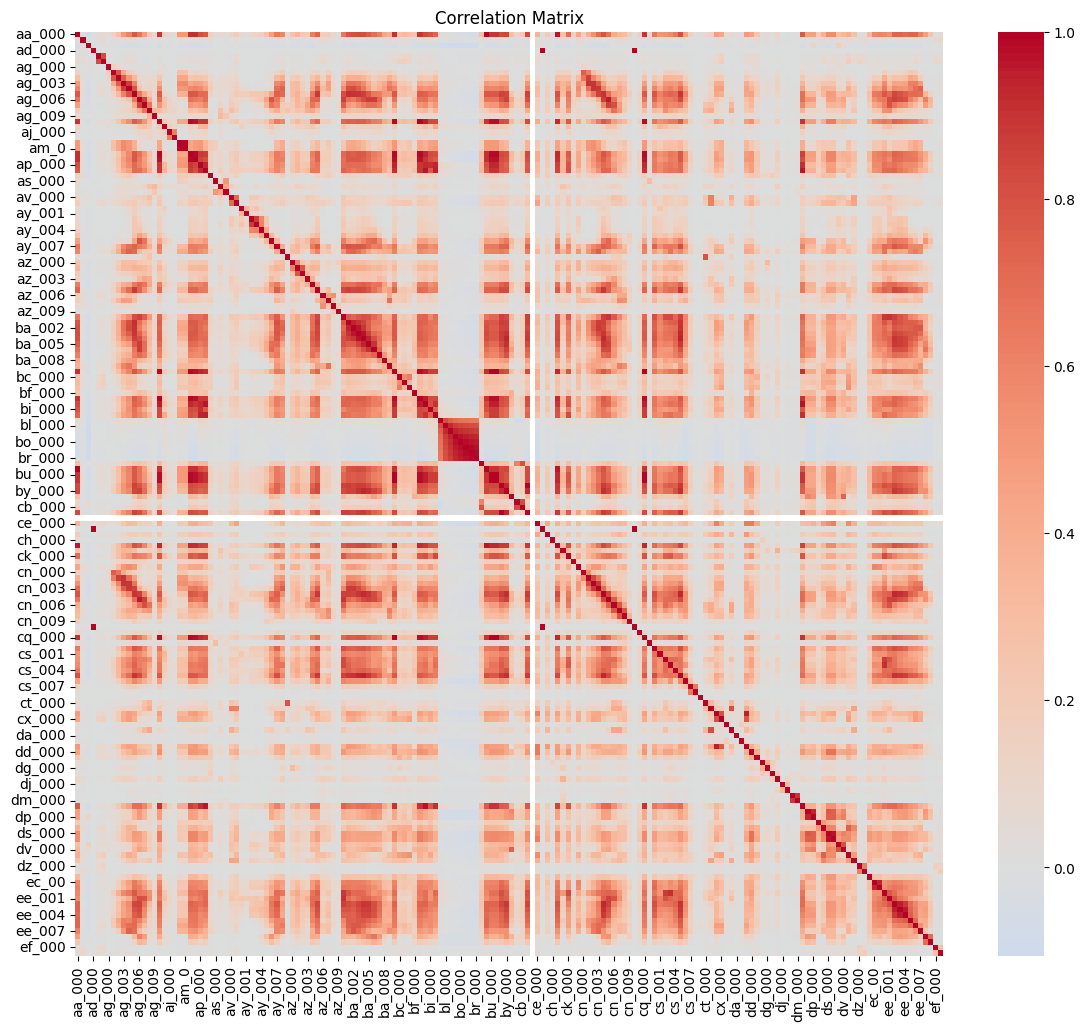

In [19]:
features = train.drop(columns = ["class"])
correlation_matrix = features.corr()

plt.figure(figsize=(14, 12))
sn.heatmap(correlation_matrix, cmap = "coolwarm", center = 0)
plt.title("Correlation Matrix")
plt.show()

#### (iv) Make scatter plots and box plots

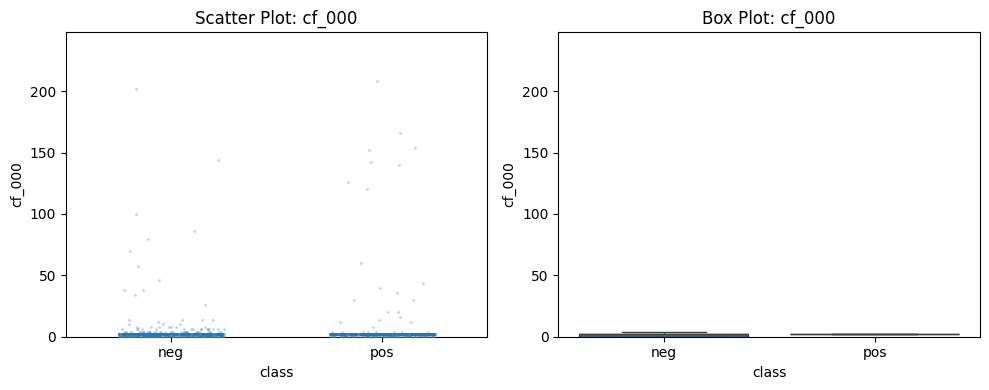

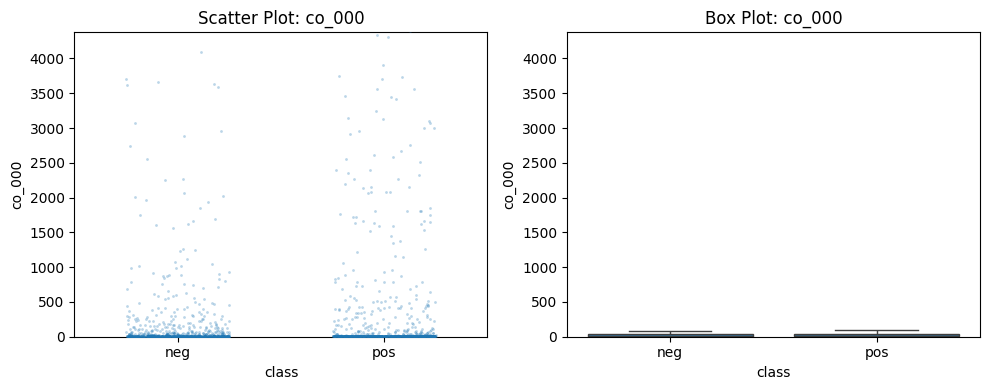

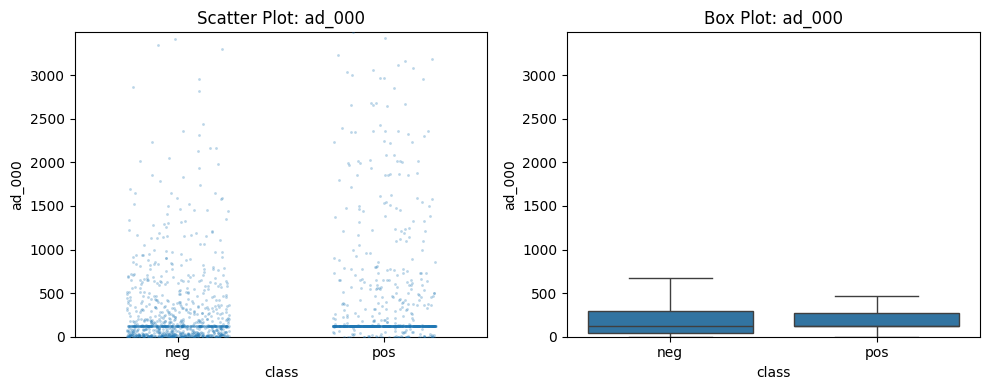

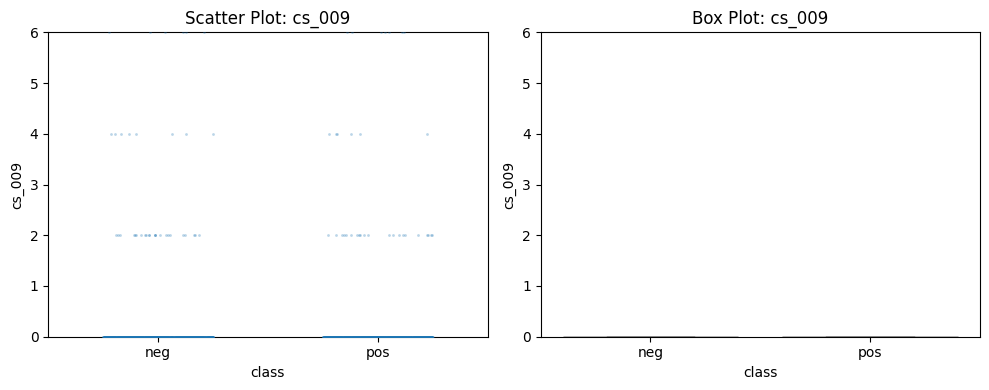

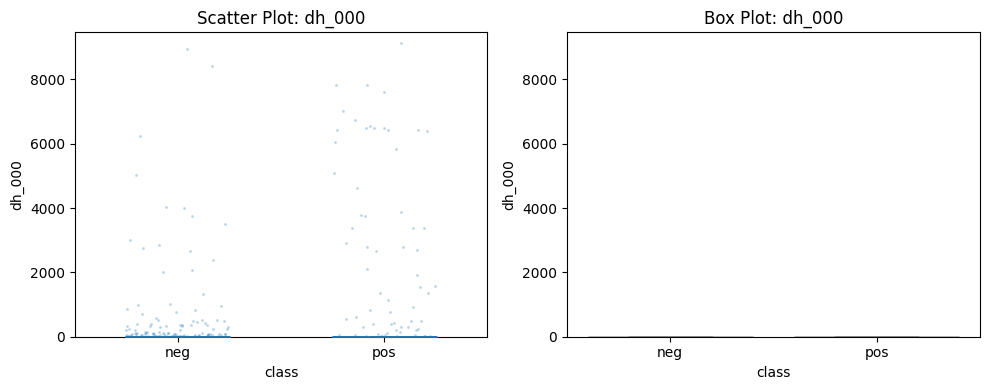

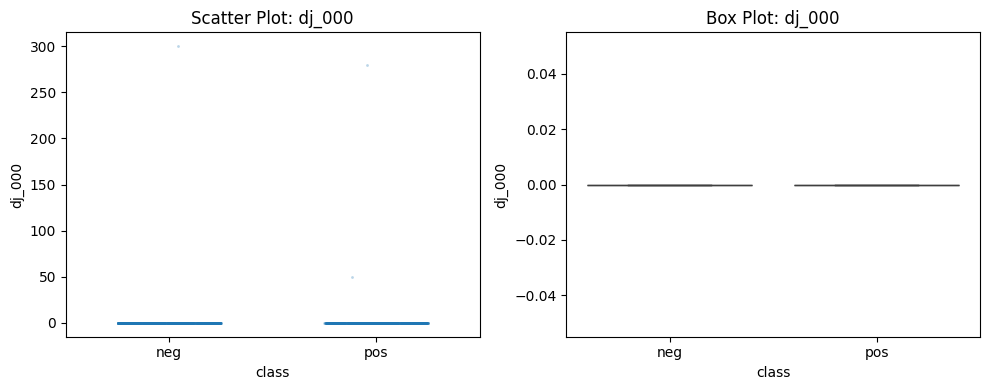

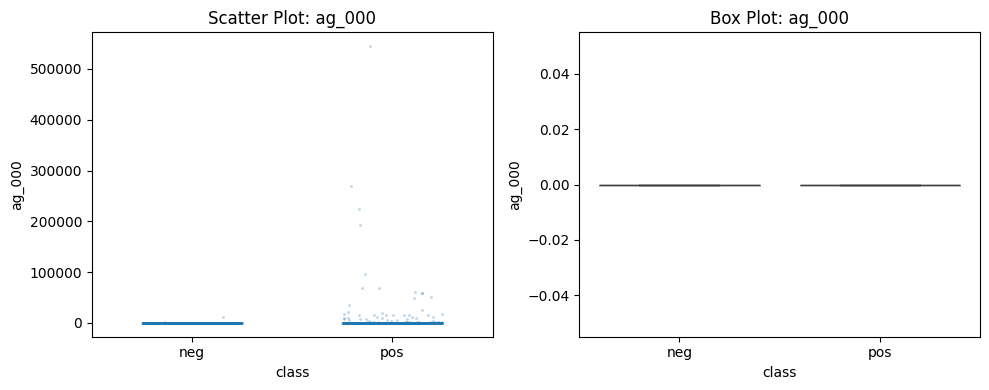

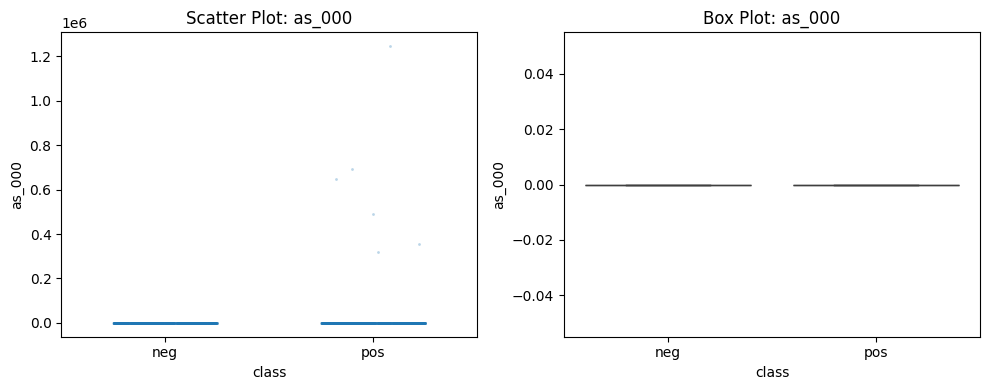

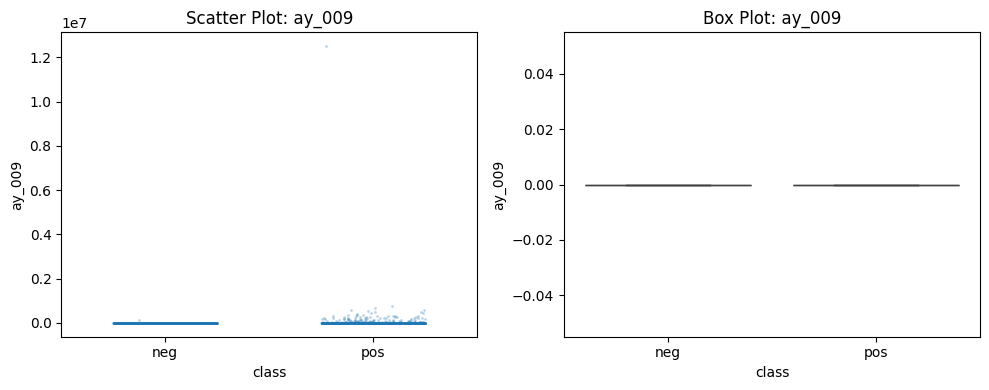

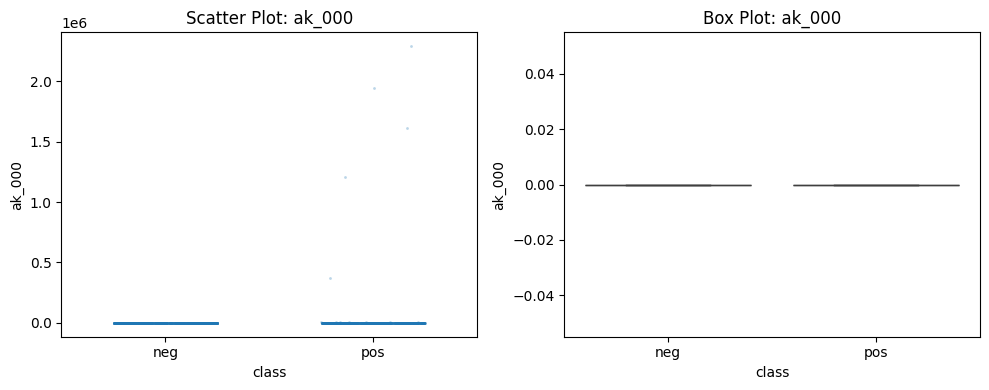

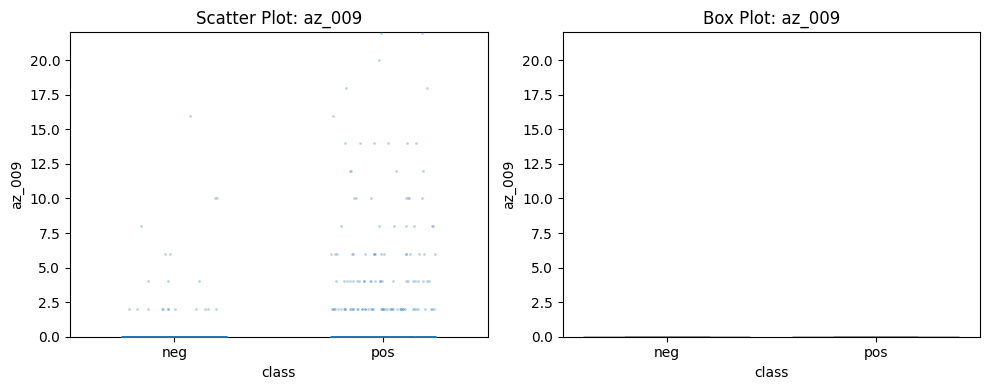

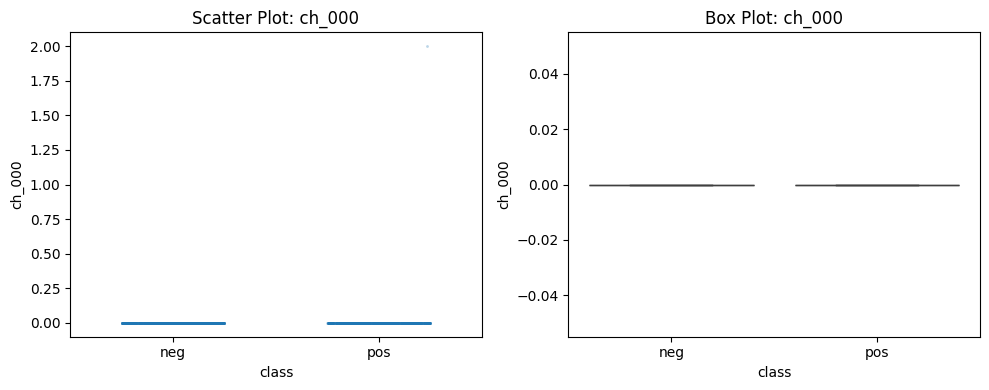

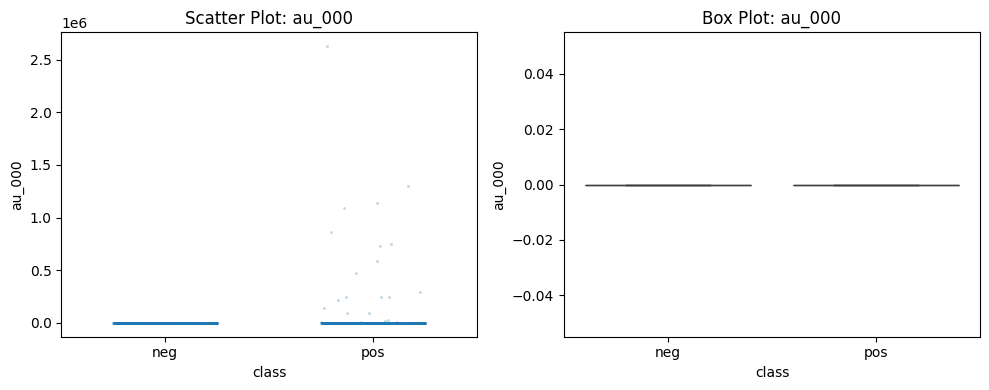

In [20]:
features = train.drop(columns = ["class"])
cv = features.std() / features.mean()

number_of_features = int(170 ** 0.5)
top_features = cv.nlargest(number_of_features).index

sample_size = train["class"].value_counts().min()
plot_data = train.groupby("class", group_keys = False).sample(n = sample_size, random_state = 1018)

for feature in top_features:
    lower = train[feature].quantile(0.01)
    upper = train[feature].quantile(0.99)

    plt.figure(figsize = (10, 4))

    plt.subplot(1, 2, 1)
    sn.stripplot(data = plot_data, x = "class", y = feature, jitter = 0.25, alpha = 0.3, size = 2)
    if lower < upper:
      plt.ylim(lower, upper)
    plt.title("Scatter Plot: " + feature)
    plt.subplot(1, 2, 2)
    sn.boxplot(data = train, x = "class", y = feature, showfliers = False)
    if lower < upper:
      plt.ylim(lower, upper)
    plt.title("Box Plot: " + feature)
    plt.tight_layout()
    plt.show()

For ay_009, most of the values are very close to zero, but there are some much larger values in the positive class, including one really large outlier. The box plot shows that the typical values for both classes are still close to zero. So, the feature might show some difference between the classes, but the plots alone aren't enough to say if it is significant for predicting failure.

#### (v) Is this data set imbalanced?

In [21]:
positive = (train["class"] == "pos").sum()
negative = (train["class"] == "neg").sum()

print("Positive:", positive)
print("Negative:", negative)

Positive: 1000
Negative: 59000


The training set has 1,000 positive samples and 59,000 negative samples, so it is imbalanced, since most of the data belongs the the negative class.

### (c) Train a random forest

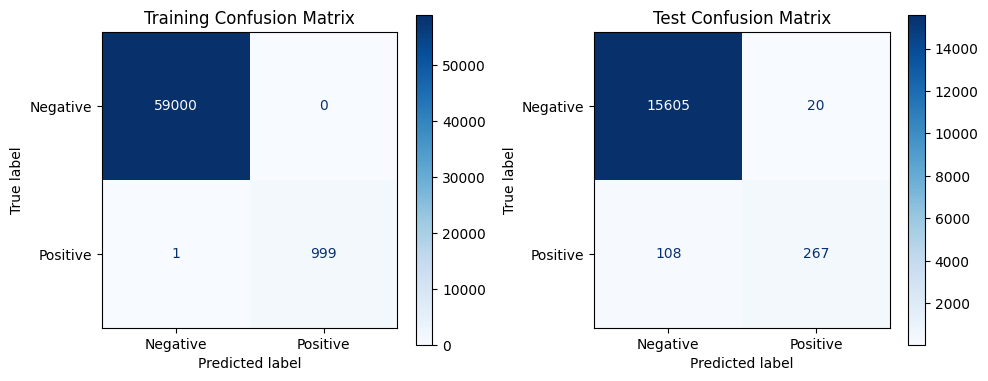

Training misclassification: 1.6666666666666667e-05
Test misclassification: 0.008
Training AUC: 1.0
Test AUC: 0.9930297173333333


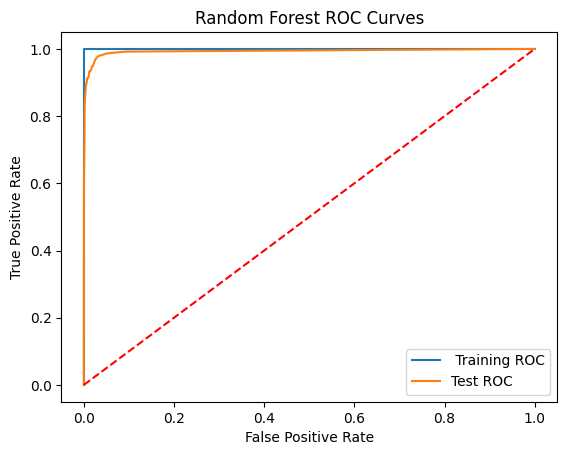

OOB error: 0.006266666666666643
Test error: 0.008


In [22]:
X_train = train.drop(columns = ["class"])
y_train = train["class"]

X_test = test.drop(columns=["class"])
y_test = test["class"]

rf = RandomForestClassifier(n_estimators = 100, bootstrap = True, oob_score = True, random_state = 1018)
rf.fit(X_train, y_train)

train_predictions = rf.predict(X_train)
test_predictions = rf.predict(X_test)

positive_index = list(rf.classes_).index("pos")
train_probabilities = rf.predict_proba(X_train)[:, positive_index]
test_probabilities = rf.predict_proba(X_test)[:, positive_index]

fig, axes = plt.subplots(1, 2, figsize = (10, 4))

ConfusionMatrixDisplay.from_predictions(y_train, train_predictions, labels = ["neg", "pos"], display_labels = ["Negative", "Positive"], values_format = "d", cmap = "Blues",ax = axes[0])
axes[0].set_title("Training Confusion Matrix")
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, labels = ["neg", "pos"], display_labels = ["Negative", "Positive"], values_format = "d", cmap = "Blues",ax = axes[1])
axes[1].set_title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

train_error = np.mean(train_predictions != y_train)
test_error = np.mean(test_predictions != y_test)

print("Training misclassification:", train_error)
print("Test misclassification:", test_error)

train_auc = roc_auc_score(y_train == "pos", train_probabilities)
test_auc = roc_auc_score(y_test == "pos", test_probabilities)

print("Training AUC:", train_auc)
print("Test AUC:", test_auc)

train_fpr, train_tpr, _ = roc_curve(y_train, train_probabilities, pos_label = "pos")
test_fpr, test_tpr, _ = roc_curve(y_test, test_probabilities, pos_label = "pos")

plt.plot(train_fpr, train_tpr, label = " Training ROC")
plt.plot(test_fpr, test_tpr, label = "Test ROC")
plt.plot([0, 1], [0, 1], "--", color  = "red")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

oob_error = 1 - rf.oob_score_
print("OOB error:", oob_error)
print("Test error:", test_error)

### (d) Research class imbalance in random forest

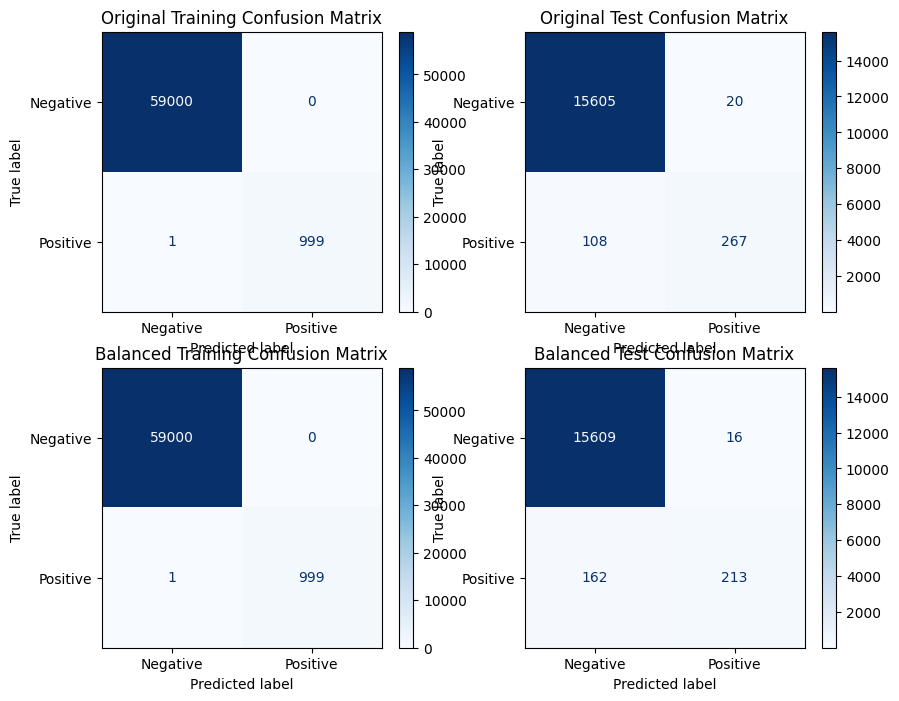

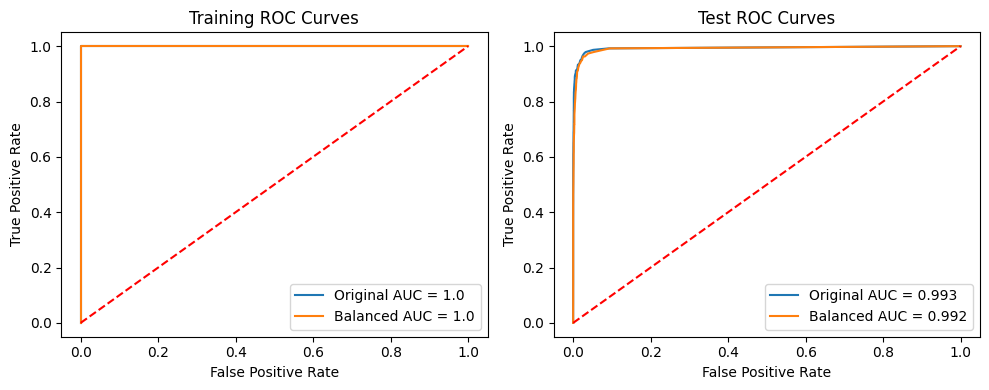

          Training error  Test error  Training AUC  Test AUC  OOB error
Original        0.000017    0.008000           1.0  0.993030   0.006267
Balanced        0.000017    0.011125           1.0  0.991599   0.007767


In [23]:
X_train = train.drop(columns = ["class"])
y_train = train["class"]

X_test = test.drop(columns = ["class"])
y_test = test["class"]

models = {"Original": RandomForestClassifier(n_estimators = 100, bootstrap = True, oob_score = True, random_state = 1018), "Balanced": RandomForestClassifier(n_estimators = 100, bootstrap = True, oob_score = True, class_weight = "balanced", random_state = 1018)}
results = {}

fig, confusion_axes = plt.subplots(2, 2, figsize = (10, 8))
roc_fig, roc_axes = plt.subplots(1, 2, figsize = (10, 4))

for row, (name, model) in enumerate(models.items()):
    model.fit(X_train, y_train)
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    positive_index = list(model.classes_).index("pos")
    train_probabilities = model.predict_proba(X_train)[:, positive_index]
    test_probabilities = model.predict_proba(X_test)[:, positive_index]

    results[name] = {"Training error": np.mean(train_predictions != y_train), "Test error": np.mean(test_predictions != y_test), "Training AUC": roc_auc_score(y_train == "pos", train_probabilities), "Test AUC": roc_auc_score(y_test == "pos", test_probabilities), "OOB error": 1 - model.oob_score_}

    ConfusionMatrixDisplay.from_predictions(y_train, train_predictions, labels = ["neg", "pos"], display_labels = ["Negative", "Positive"], values_format = "d", cmap = "Blues",ax = confusion_axes[row, 0])
    confusion_axes[row, 0].set_title(name + " Training Confusion Matrix")
    ConfusionMatrixDisplay.from_predictions(y_test, test_predictions,labels = ["neg", "pos"], display_labels = ["Negative", "Positive"], values_format = "d", cmap = "Blues", ax = confusion_axes[row, 1])
    confusion_axes[row, 1].set_title(name + " Test Confusion Matrix")

    train_fpr, train_tpr, _ = roc_curve(y_train, train_probabilities, pos_label = "pos")
    test_fpr, test_tpr, _ = roc_curve(y_test, test_probabilities, pos_label = "pos")

    roc_axes[0].plot(train_fpr, train_tpr, label = name + " AUC = " + str(round(results[name]["Training AUC"], 3)))
    roc_axes[1].plot(test_fpr, test_tpr, label = name + " AUC = " + str(round(results[name]["Test AUC"], 3)))

plt.tight_layout()


for ax in roc_axes:
    ax.plot([0, 1], [0, 1], "--", color = "red")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()

roc_axes[0].set_title("Training ROC Curves")
roc_axes[1].set_title("Test ROC Curves")
plt.tight_layout()
plt.show()

print(pd.DataFrame(results).T)

The balanced random forest gives more weight to the positive class because there are way fewer positive examples, but its test error was slightly higher than the original model's (1.1% vs. 0.8%). Both models still had very high test AUCs, so they both did a good job separating the classes overall. The balanced model didn't improve these results, but it may catch more positive cases, which can be seen in the confusion matricies.

### (e) XGBoost and Model Trees

Best alpha: 0.01
5-fold CV error: 0.006749999999999923
Training error: 0.004483333333333333
Test error: 0.0084375
Training AUC: 0.9959458305084745
Test AUC: 0.995506688


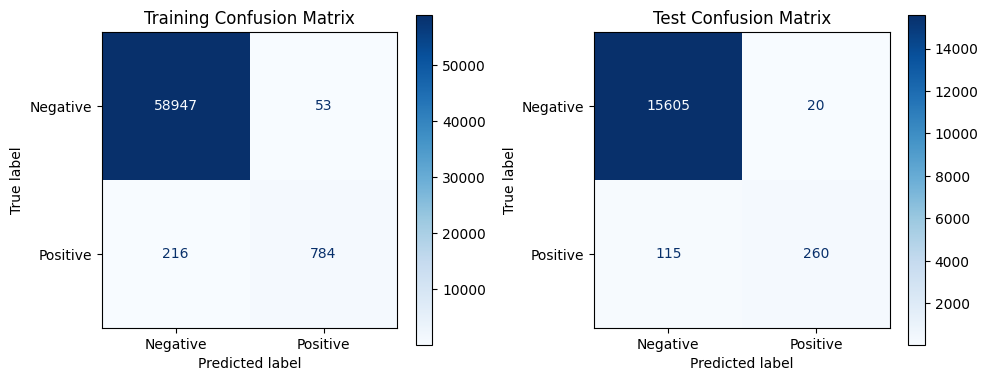

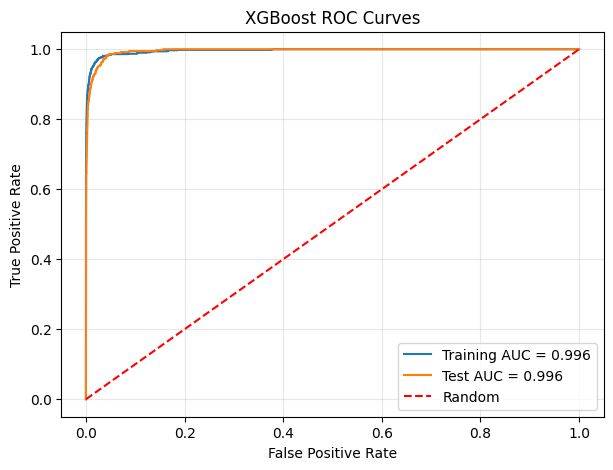

In [24]:
X_train = train.drop(columns = ["class"])
y_train = (train["class"] == "pos").astype(int)

X_test = test.drop(columns = ["class"])
y_test = (test["class"] == "pos").astype(int)

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 1018)

model = XGBClassifier(objective = "binary:logistic", eval_metric = "logloss", scale_pos_weight = 1, n_estimators = 100, max_depth = 3, learning_rate = 0.1, random_state = 1018, n_jobs = 1, tree_method = "hist")
parameters = {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]}
search = GridSearchCV(model, parameters, scoring = "accuracy", cv = cv, n_jobs = -1)
search.fit(X_train, y_train)

best_model = search.best_estimator_

print("Best alpha:", search.best_params_["reg_alpha"])
print("5-fold CV error:", 1 - search.best_score_)

train_predictions = best_model.predict(X_train)
test_predictions = best_model.predict(X_test)

train_probabilities = best_model.predict_proba(X_train)[:, 1]
test_probabilities = best_model.predict_proba(X_test)[:, 1]

train_error = np.mean(train_predictions != y_train)
test_error = np.mean(test_predictions != y_test)

print("Training error:", train_error)
print("Test error:", test_error)

train_auc = roc_auc_score(y_train, train_probabilities)
test_auc = roc_auc_score(y_test, test_probabilities)

print("Training AUC:", train_auc)
print("Test AUC:", test_auc)

fig, axes = plt.subplots(1, 2, figsize = (10, 4))

ConfusionMatrixDisplay.from_predictions(y_train, train_predictions, labels = [0, 1], display_labels = ["Negative", "Positive"], values_format = "d", cmap = "Blues", ax = axes[0])
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, labels = [0, 1], display_labels = ["Negative", "Positive"], values_format = "d", cmap = "Blues", ax = axes[1])
axes[1].set_title("Test Confusion Matrix")
plt.tight_layout()

train_fpr, train_tpr, _ = roc_curve(y_train, train_probabilities)
test_fpr, test_tpr, _ = roc_curve(y_test, test_probabilities)

plt.figure(figsize = (7, 5))
plt.plot(train_fpr, train_tpr, label = "Training AUC = " + str(round(train_auc, 3)))
plt.plot(test_fpr, test_tpr, label = "Test AUC = " + str(round(test_auc, 3)))
plt.plot([0, 1], [0, 1], "--", color = "red", label = "Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

### (f) Use SMOTE to pre-process your data

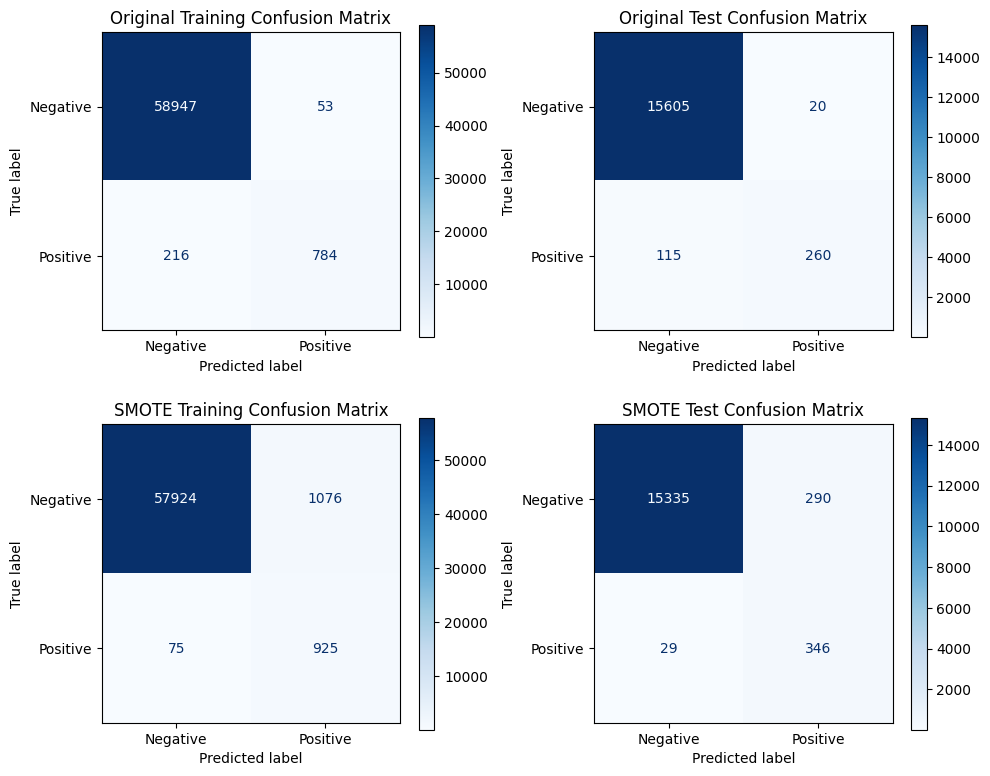

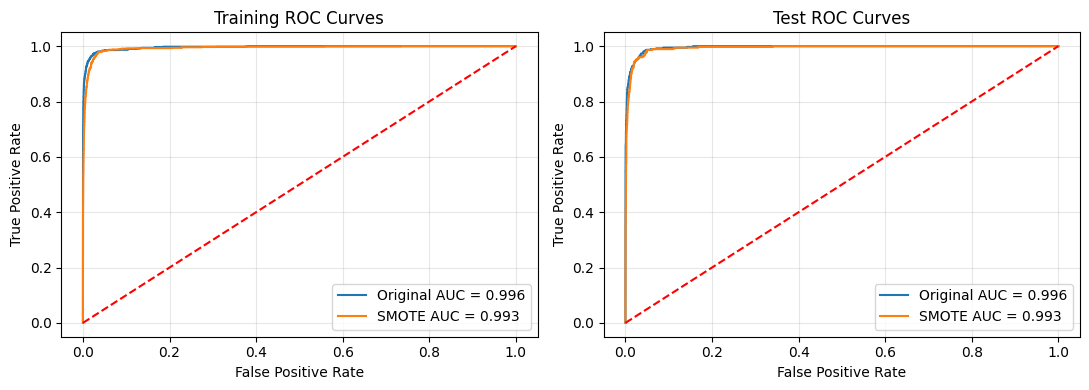

          Best alpha  10-fold CV error  Training error  Test error  \
Original        0.01          0.006750        0.004483    0.008438   
SMOTE           1.00          0.020433        0.019183    0.019938   

          Training AUC  Test AUC  
Original      0.995946  0.995507  
SMOTE         0.993138  0.993449  


In [25]:
X_train = train.drop(columns = ["class"])
y_train = (train["class"] == "pos").astype(int)

X_test = test.drop(columns = ["class"])
y_test = (test["class"] == "pos").astype(int)

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 1018)

alphas = [0, 0.01, 0.1, 1, 10]

original_model = XGBClassifier(objective = "binary:logistic", eval_metric = "logloss", scale_pos_weight = 1, n_estimators = 100, max_depth = 3, learning_rate = 0.1, random_state = 1018, n_jobs = 1, tree_method = "hist")
original_search = GridSearchCV(original_model, {"reg_alpha": alphas}, scoring = "accuracy", cv = cv, n_jobs = -1)

smote_pipeline = Pipeline([("smote", SMOTE(random_state=1)), ("xgb", XGBClassifier(objective = "binary:logistic", eval_metric = "logloss", scale_pos_weight = 1, n_estimators = 100, max_depth = 3, learning_rate = 0.1, random_state = 1018, n_jobs = 1, tree_method = "hist"))])
smote_search = GridSearchCV(smote_pipeline, {"xgb__reg_alpha": alphas}, scoring = "accuracy", cv = cv, n_jobs = -1)

searches = {"Original": original_search, "SMOTE": smote_search}

results = {}
roc_data = {}

fig, confusion_axes = plt.subplots(2, 2, figsize = (10, 8))

for row, (name, search) in enumerate(searches.items()):
    search.fit(X_train, y_train)
    model = search.best_estimator_

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_probabilities = model.predict_proba(X_train)[:, 1]
    test_probabilities = model.predict_proba(X_test)[:, 1]

    train_auc = roc_auc_score(y_train, train_probabilities)
    test_auc = roc_auc_score(y_test, test_probabilities)

    if name == "Original":
        best_alpha = search.best_params_["reg_alpha"]
    else:
        best_alpha = search.best_params_["xgb__reg_alpha"]

    results[name] = {"Best alpha": best_alpha, "10-fold CV error": 1 - search.best_score_, "Training error": np.mean(train_predictions != y_train), "Test error": np.mean(test_predictions != y_test), "Training AUC": train_auc, "Test AUC": test_auc}

    ConfusionMatrixDisplay.from_predictions(y_train, train_predictions, labels = [0, 1], display_labels = ["Negative", "Positive"], values_format = "d", cmap = "Blues", ax = confusion_axes[row, 0])
    confusion_axes[row, 0].set_title(name + " Training Confusion Matrix")

    ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, labels = [0, 1], display_labels = ["Negative", "Positive"], values_format = "d", cmap = "Blues", ax = confusion_axes[row, 1])
    confusion_axes[row, 1].set_title(name + " Test Confusion Matrix")

    train_fpr, train_tpr, _ = roc_curve(y_train, train_probabilities)
    test_fpr, test_tpr, _ = roc_curve(y_test, test_probabilities)

    roc_data[name] = {"train_fpr": train_fpr, "train_tpr": train_tpr, "test_fpr": test_fpr, "test_tpr": test_tpr, "train_auc": train_auc, "test_auc": test_auc}

plt.tight_layout()

fig, axes = plt.subplots(1, 2, figsize = (11, 4))

for name, values in roc_data.items():
    axes[0].plot(values["train_fpr"], values["train_tpr"], label = name + " AUC = " + str(round(values["train_auc"], 3)))
    axes[1].plot(values["test_fpr"], values["test_tpr"], label = name + " AUC = " + str(round(values["test_auc"], 3)))

for ax in axes:
    ax.plot([0, 1], [0, 1], "--", color = "red")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()
    ax.grid(True, alpha = 0.3)

axes[0].set_title("Training ROC Curves")
axes[1].set_title("Test ROC Curves")

plt.tight_layout()
plt.show()
print(pd.DataFrame(results).T)

## 2. ISLR 6.6.3

A. Steadily decrease because as s gets bigger, the model is allowed to use larger coefficients, so it can fit the training data better and the training RSS goes down.

B. Decrease at first, then increase in a U shape because at first, the model fits better. But if s gets too big, the model can start fitting to noise instead, which can make the test RSS go up.

C. Steadily increase since a less restricted model can change more depending on the training data, so its variance will increase.

D. Steadily decrease because as the model becomes less restricted, it can fit the data better, so its squared bias goes down.

E. Remain constant since irreducible error comes from randomness in the data, so changing s does not change it.

## 3. ISLR 6.6.5

A. minB1B2(y1 - x11B1 - x12B2)^2 + (y2 - x21B1 - x22B2)^2 + lambda(B1^2 + B2^2), which then simplifies to min2B1B2(y - x(B1 + B2)^2) + lambda(B1^2 + B2^2).

B. B1^2 + B2^2 = 1/2(B1 + B2)^2 1/2(B1 - B2)^2, and this is smallest when B1 - B2 = 0, which means that the ridge coefficents B1 = B2.

C. min2B1B2(y - x(B1 + B2)^2) + lambda(|B1| + |B2|)

D. The predictions depend on B1 + B2, so different coefficients can make the same predictions if their sum stays the same. When both coefficients have the same sign, their lasso penalty also stays the same, so there can be many lasso solutions.

## 4. ISLR 8.4.5

If probabilty > 0.5, predict red and if < 0.5 pick green. Since 6 trees predict red and 4 predict green, using the majoirty vote the prediction is red. For the average probability do 0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + + 0.75 / 10 = 0.45 < 0.5 so predict green.

## 5. ISLR 9.7.3

Contains solutions A-H

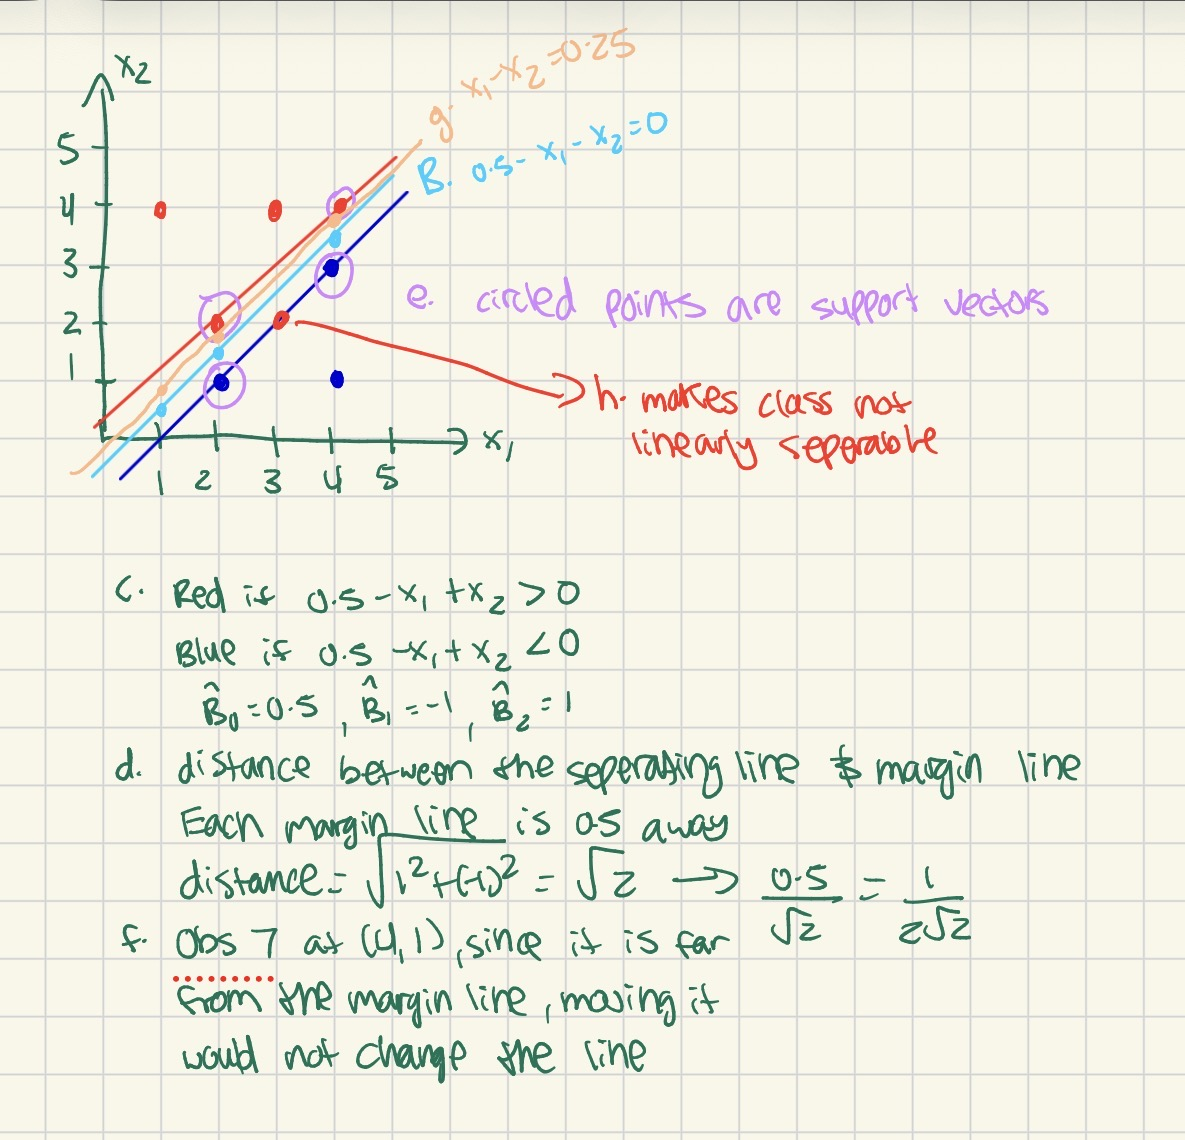